# Рекомендации по содержанию товаров

Содержательная модель сопоставляет характеристики товаров с профилем конкретного пользователя. Здесь профиль строится по прошлым взаимодействиям, а новые кандидаты сравниваются с ним без обращения к будущим покупкам.

TF-IDF, разреженные матрицы и косинусная близость изучены в модуле анализа текста. В этом файле они применяются к новой задаче: построению профиля, учёту давности, объяснению рекомендации и работе с товаром без истории взаимодействий.

Файл выполняется независимо. Требуются только включённые в комплект reco_catalog.csv и reco_events.csv. Генерация этих данных и общий протокол разобраны в первом ноутбуке.

## Признаки товара и доступность содержания

Наблюдаемая история пользователя и описание кандидата выполняют разные роли. История определяет профиль, каталог задаёт пространство свойств. Описание нового товара может быть известно раньше первого взаимодействия с ним.

Поле no_train_events оставлено только для диагностики холодного старта. Оно не входит в признаки и не сообщает алгоритму скрытое качество товара.

In [1]:
# Шаг М4.02.01 — Среда и общий протокол
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
module_name = "Модуль 4 Рекомендательные системы"
candidates = [candidate for root in [Path.cwd(), *Path.cwd().parents]
              for candidate in (root, root / "course" / "practice" / module_name)]
MODULE_DIR = next(p for p in candidates if p.name == module_name and p.is_dir())
DATA_DIR = MODULE_DIR / "data"
SOURCE_DIR = MODULE_DIR.parent.parent / "data"
print("Каталог материалов:", MODULE_DIR.name)


def load_context(phase="validation"):
    if phase not in {"validation", "test"}:
        raise ValueError("Ожидается validation или test")
    catalog = pd.read_csv(DATA_DIR / "reco_catalog.csv").sort_values("product_id").reset_index(drop=True)
    events = pd.read_csv(DATA_DIR / "reco_events.csv", parse_dates=["timestamp"]).drop_duplicates("event_id")
    cut = pd.Timestamp("2025-04-01" if phase == "validation" else "2025-05-01")
    end = pd.Timestamp("2025-05-01" if phase == "validation" else "2025-06-01")
    history = events[events.timestamp < cut].copy()
    future = events[(events.timestamp >= cut) & (events.timestamp < end) & (events.event_type == "purchase")]
    user_ids = np.arange(1, 301)  # Известный учебный реестр, а не признак предпочтения.
    item_ids = catalog.product_id.to_numpy()
    u_map = {int(value): index for index, value in enumerate(user_ids)}
    i_map = {int(value): index for index, value in enumerate(item_ids)}
    history["strength"] = history.event_type.map({"view": 1.0, "cart": 3.0, "purchase": 5.0})
    pairs = history.groupby(["user_id", "product_id"]).strength.sum().reset_index()
    R = sparse.csr_matrix((np.log1p(pairs.strength),
                           (pairs.user_id.map(u_map), pairs.product_id.map(i_map))),
                          shape=(len(user_ids), len(item_ids)))
    B = R.copy()
    B.data[:] = 1.0
    seen = B.toarray().astype(bool)  # Только 300 x 180; полный большой каталог так не разворачивается.
    truth = {int(u): set(g.product_id) - set(item_ids[seen[u_map[int(u)]]])
             for u, g in future.groupby("user_id")}
    purchases = history[history.event_type.eq("purchase")].drop_duplicates(["user_id", "product_id"])
    popularity = purchases.groupby("product_id").size().reindex(item_ids, fill_value=0).to_numpy(float)
    return dict(catalog=catalog, events=events, history=history, R=R, B=B, seen=seen,
                truth=truth, user_ids=user_ids, item_ids=item_ids, u_map=u_map,
                i_map=i_map, popularity=popularity, cut=cut, end=end, phase=phase)

def top_indices(scores, seen, k=10):
    values = np.array(scores, dtype=float, copy=True)
    if values.ndim != 2 or values.shape != seen.shape or not np.isfinite(values).all():
        raise ValueError("Нужна конечная матрица оценок формы user x item")
    values[seen] = -np.inf
    result = []
    for row in values:
        order = np.argsort(-row, kind="stable")
        result.append(order[np.isfinite(row[order])][:k])
    return result

def evaluate(scores, ctx, k=10):
    ranked = top_indices(scores, ctx["seen"], k)
    rows = []
    for u, relevant in ctx["truth"].items():
        if not relevant:
            continue
        ui = ctx["u_map"][u]
        recommended = ctx["item_ids"][ranked[ui]]
        hits = np.isin(recommended, list(relevant)).astype(float)
        discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
        ideal = (1 / np.log2(np.arange(2, min(k, len(relevant)) + 2))).sum()
        positions = np.flatnonzero(hits)
        rows.append(dict(user_id=u, history_size=int(ctx["seen"][ui].sum()), n_truth=len(relevant),
                         precision=float(hits.sum()/k), recall=float(hits.sum()/len(relevant)),
                         ndcg=float(hits @ discounts / ideal), hit=float(hits.any()),
                         mrr=0.0 if not len(positions) else 1.0/(positions[0]+1)))
    return pd.DataFrame(rows)

def summarize(scores, ctx, k=10):
    detail = evaluate(scores, ctx, k)
    ranked = top_indices(scores, ctx["seen"], k)
    evaluated_rows = [ranked[ctx["u_map"][int(u)]] for u in detail.user_id]
    chosen = np.concatenate(evaluated_rows)
    novelty = -np.log2((ctx["popularity"]+1)/(ctx["popularity"].sum()+len(ctx["item_ids"])))
    return pd.Series({"Precision@K":detail.precision.mean(), "Recall@K":detail.recall.mean(),
                      "NDCG@K":detail.ndcg.mean(), "HitRate@K":detail.hit.mean(),
                      "Coverage":len(np.unique(chosen))/len(ctx["item_ids"]),
                      "Novelty":float(novelty[chosen].mean()), "users":len(detail)})

def popular_scores(ctx):
    return np.tile(ctx["popularity"], (len(ctx["user_ids"]), 1))

Каталог материалов: Модуль 4 Рекомендательные системы


Содержательная модель использует свойства, доступные до взаимодействия. Данные каталога могут быть известны для товара без покупок, что отличает их от поведенческой статистики. Синтетические коллекции служат именно такой заранее доступной информацией.

Диагностический флаг no_train_events описывает устройство эксперимента и исключён из модели. Подмена признаков условиями генерации могла бы давать внешне сильный результат без полезного механизма рекомендаций.

In [2]:
# Шаг М4.02.02 — Карточки и учебные свойства
ctx=load_context("validation")
catalog=ctx["catalog"]
display(catalog[["product_id","name","category","price","collection","usage","no_train_events"]].head(10))
print("Карточек:",len(catalog),"Холодных по взаимодействиям:",int(catalog.no_train_events.sum()))

,product_id,name,category,price,collection,usage,no_train_events
0,1,Электроника товар 1,Электроника,61790,базовая,дом,False
1,2,Обувь товар 2,Обувь,15690,базовая,дом,False
2,3,Электроника товар 3,Электроника,29120,активная,поездка,False
3,4,Книги товар 4,Книги,1760,базовая,дом,False
4,5,Продукты товар 5,Продукты,1680,базовая,дом,False
5,6,Продукты товар 6,Продукты,2320,активная,поездка,False
6,7,Продукты товар 7,Продукты,1790,уютная,подарок,False
7,8,Бытовая техника товар 8,Бытовая техника,56240,базовая,дом,False
8,9,Электроника товар 9,Электроника,98560,уютная,подарок,False
9,10,Одежда товар 10,Одежда,12310,базовая,дом,False


Карточек: 180 Холодных по взаимодействиям: 9


Уникальное имя с номером не обязательно богато содержанием. Включение числового идентификатора в документ в основном создаёт отдельный токен карточки. Он не связывает новый товар с похожими объектами.

Категория, коллекция и сценарий образуют описание, а цена остаётся числовым значением. Такое разделение позволяет контролировать смысл каждого вида сходства вместо произвольного смешения текстовых записей и чисел.

In [3]:
# Шаг М4.02.03 — Почему идентификатор не является смысловым признаком
display(pd.DataFrame({
    "поле":["product_id","name","category","collection","usage","price"],
    "использование":["Ключ связи; не токен предпочтения","Почти шаблонное имя; не включено",
                     "Признак содержания","Учебный признак содержания","Учебный признак содержания",
                     "Отдельная числовая проверка, не текст"]}))
documents=catalog.category+" "+catalog.collection+" "+catalog.usage
display(documents.head(6).to_frame("документ товара"))

,поле,использование
0,product_id,Ключ связи; не токен предпочтения
1,name,Почти шаблонное имя; не включено
2,category,Признак содержания
3,collection,Учебный признак содержания
4,usage,Учебный признак содержания
5,price,"Отдельная числовая проверка, не текст"


,документ товара
0,Электроника базовая дом
1,Обувь базовая дом
2,Электроника активная поездка
3,Книги базовая дом
4,Продукты базовая дом
5,Продукты активная поездка


Векторы товаров строятся в едином словаре. Новая карточка может быть преобразована тем же векторизатором, если её признаки представлены в словаре. Неизвестные слова не создают автоматически новых координат уже обученного пространства.

Разбиение многословной категории на токены является конкретным модельным решением. При необходимости строгого сравнения категорий по одному значению требуется отдельное категориальное кодирование, а не предположение, что текстовая запись всегда эквивалентна ему.

In [4]:
# Шаг М4.02.04 — Векторное пространство каталога
vectorizer=TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
F=vectorizer.fit_transform(documents)
features=vectorizer.get_feature_names_out()
display(pd.Series({"товаров":F.shape[0],"признаков":F.shape[1],"ненулевых значений":F.nnz,
                   "плотность":F.nnz/np.prod(F.shape)}).to_frame("значение"))
display(pd.DataFrame(F[:5].toarray(),columns=features,index=catalog.product_id.head(5)))

,значение
товаров,180.000000
признаков,18.000000
ненулевых значений,593.000000
плотность,0.183025


,активная,базовая,бытовая,дом,и,книги,красота,обувь,одежда,подарок,поездка,премиальная,продукты,сад,спорт,техника,уютная,электроника
product_id,,,,,,,,,,,,,,,,,,
1,0.000000,0.54363,0.0,0.425455,0.0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.723502
2,0.000000,0.54363,0.0,0.425455,0.0,0.000000,0.0,0.723502,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000
3,0.533613,0.00000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.459254,0.0,0.000000,0.0,0.0,0.0,0.0,0.710171
4,0.000000,0.54363,0.0,0.425455,0.0,0.723502,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000
5,0.000000,0.54363,0.0,0.425455,0.0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.723502,0.0,0.0,0.0,0.0,0.000000


Соседство одного товара полезно для блока похожих карточек. Пользовательская выдача решает более широкую задачу: у человека может быть история из нескольких разных объектов. Сведение её к одному якорю является отдельным упрощающим предположением.

Результат отражает только представленные свойства. Различие цены не учитывается в этом сходстве, а различие размера или совместимости не может учитываться без соответствующих полей.

In [5]:
# Шаг М4.02.05 — Соседство по содержанию
anchor=0
item_similarity=cosine_similarity(F[anchor],F).ravel()
order=np.argsort(-item_similarity,kind="stable")
order=order[order!=anchor][:8]
display(catalog.iloc[order][["product_id","category","collection","usage"]]
        .assign(сходство=item_similarity[order]))

,product_id,category,collection,usage,сходство
79,80,Электроника,базовая,дом,1.000000
29,30,Электроника,базовая,поездка,0.803898
112,117,Электроника,базовая,поездка,0.803898
60,61,Электроника,базовая,подарок,0.791142
22,23,Электроника,премиальная,дом,0.704467
56,57,Электроника,уютная,дом,0.704467
64,65,Электроника,активная,дом,0.704467
108,113,Электроника,премиальная,дом,0.704467


## Пользовательский профиль и объяснение выдачи

Профиль — нормированная взвешенная сумма векторов прошлых товаров: profile(u) = normalize(Σ R_ui · F_i). Оценка кандидата равна скалярному произведению нормированного профиля с его нормированным вектором.

Профиль усредняет интересы. Он может потерять редкую потребность или смешать несовместимые сценарии. Интерпретация результата требует просмотра вкладов и фактической истории.

Функция возвращает профиль, признаки и оценки вместе, чтобы результат оставался проверяемым. Параметр давности действует на события до объединения повторов пары, ценовой штраф меняет итоговый скоринг кандидата.

Для нулевой истории задаётся популярность. Возврат произвольной десятки при равных нулевых оценках был бы техническим следствием сортировки, а не моделью интересов. Источник такой неперсональной выдачи должен быть явно обозначен.

In [6]:
# Шаг М4.02.06 — Полная функция содержательного алгоритма
def fit_content(ctx, half_life=None, price_penalty=0.0):
    catalog = ctx["catalog"]
    documents = catalog.category + " " + catalog.collection + " " + catalog.usage
    vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
    F = vectorizer.fit_transform(documents)
    hist = ctx["history"].copy()
    strength = hist.strength.to_numpy()
    if half_life is not None:
        age = (ctx["cut"] - hist.timestamp).dt.total_seconds().to_numpy()/86400
        strength = strength * np.exp2(-age/half_life)
    hist["weighted"] = strength
    pairs = hist.groupby(["user_id","product_id"]).weighted.sum().reset_index()
    Rw = sparse.csr_matrix((np.log1p(pairs.weighted),
                           (pairs.user_id.map(ctx["u_map"]),pairs.product_id.map(ctx["i_map"]))),
                          shape=ctx["R"].shape)
    profiles = normalize(Rw @ F)
    scores = (profiles @ F.T).toarray()
    denominator = np.asarray(Rw.sum(axis=1)).ravel()
    log_price = np.log1p(catalog.price.to_numpy())
    typical = np.divide(np.asarray(Rw @ log_price).ravel(),denominator,
                        out=np.zeros_like(denominator),where=denominator>0)
    scores -= price_penalty*np.abs(typical[:,None]-log_price[None,:])
    cold = denominator==0
    scores[cold] = ctx["popularity"]
    return dict(scores=scores,F=F,profiles=profiles,vectorizer=vectorizer,
                weighted_history=Rw,half_life=half_life,price_penalty=price_penalty)

Исторические веса определяют вклад карточек в пользовательский профиль. Логарифмирование снижает влияние многократных действий, но не отменяет их различия. Одна покупка и один просмотр не дают одинаковый вес при принятой схеме.

Просмотр истории нужен для проверки объяснения. Заявление об интересе к свойству должно опираться на реально использованные события, а не на скрытую информацию о будущем или параметры генератора.

In [7]:
# Шаг М4.02.07 — История одного пользователя
base=fit_content(ctx)
user_id=1
ui=ctx["u_map"][user_id]
history_row=base["weighted_history"].getrow(ui)
history_view=catalog.iloc[history_row.indices][["product_id","category","collection","usage"]].copy()
history_view["вес"]=history_row.data
display(history_view.sort_values("вес",ascending=False).head(10))

,product_id,category,collection,usage,вес
4,5,Продукты,базовая,дом,1.791759
10,11,Продукты,премиальная,дом,1.791759
67,68,Продукты,базовая,дом,1.791759
62,63,Продукты,уютная,поездка,1.791759
52,53,Одежда,активная,дом,1.791759
51,52,Продукты,активная,дом,1.791759
99,103,Обувь,активная,поездка,1.791759
73,74,Одежда,базовая,дом,1.609438
71,72,Продукты,активная,поездка,1.386294
36,37,Обувь,активная,подарок,1.386294


Нормированный профиль объединяет распределение признаков разных исторических объектов. Его координаты зависят от выбранного описания, интенсивности и давности действий. Они не являются вероятностями будущих покупок.

Усреднение теряет контекст: подарок, личная покупка и временная задача могут смешиваться. Несколько профилей по намерениям или контексту потребовали бы дополнительных данных и другой постановки; один вектор не решает эту проблему автоматически.

,признак,вес
12,продукты,0.674261
0,активная,0.470854
3,дом,0.343492
8,одежда,0.211149
10,поездка,0.209274
1,базовая,0.202390
9,подарок,0.168899
7,обувь,0.160686
11,премиальная,0.096847
16,уютная,0.094641


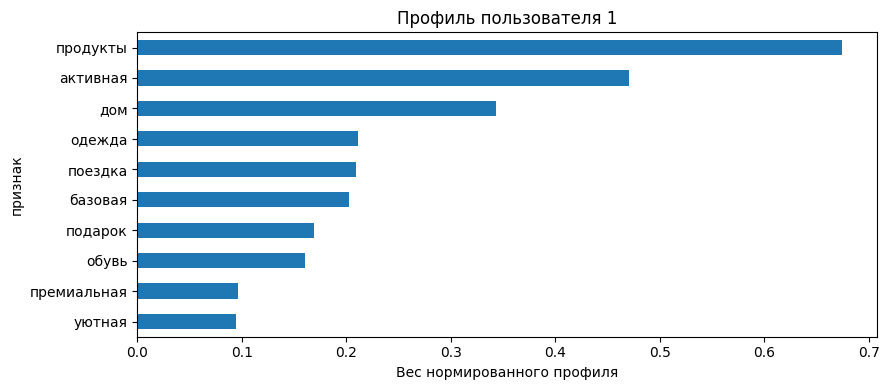

In [8]:
# Шаг М4.02.08 — Наиболее выраженные свойства профиля
profile=base["profiles"].getrow(ui).toarray().ravel()
profile_table=pd.DataFrame({"признак":base["vectorizer"].get_feature_names_out(),"вес":profile})
display(profile_table.nlargest(10,"вес"))
profile_table.nlargest(10,"вес").sort_values("вес").plot.barh(x="признак",y="вес",legend=False)
plt.title("Профиль пользователя 1");plt.xlabel("Вес нормированного профиля");plt.tight_layout();plt.show()

Каждый кандидат сравнивается с общим профилем, а затем применяется ранее заданная маска. Выдача персональна за счёт состава истории, а не потому, что у пользователя есть уникальный номер.

Высокая косинусная оценка говорит о близости представленных свойств. Она не проверяет наличие, размеры, возрастные ограничения или совместимость. Такие условия должны ограничивать кандидатов независимо от содержательного сходства.

In [9]:
# Шаг М4.02.09 — Персональные рекомендации
indices=top_indices(base["scores"],ctx["seen"],10)[ui]
display(catalog.iloc[indices][["product_id","category","collection","usage","price"]]
        .assign(оценка=base["scores"][ui,indices],
                контрольная_покупка=catalog.iloc[indices].product_id.isin(ctx["truth"][user_id]).to_numpy()))
assert not ctx["seen"][ui,indices].any()

,product_id,category,collection,usage,price,оценка,контрольная_покупка
37,38,Продукты,уютная,дом,980,0.685419,True
114,119,Продукты,уютная,дом,2300,0.685419,False
19,20,Продукты,базовая,поездка,1140,0.682948,False
98,101,Продукты,базовая,поездка,1290,0.682948,False
42,43,Продукты,базовая,подарок,1820,0.659536,False
38,39,Продукты,премиальная,поездка,1550,0.626629,True
115,120,Продукты,премиальная,поездка,620,0.626629,True
63,64,Продукты,премиальная,подарок,1940,0.604110,False
6,7,Продукты,уютная,подарок,1790,0.602952,False
72,73,Продукты,уютная,подарок,2750,0.602952,False


Произведения совпадающих координат дают точное разложение скалярного произведения. Проверка суммы отличает объяснение фактического расчёта от правдоподобного общего текста.

Это разложение относится к базовому варианту без ценового штрафа. После добавления отдельного штрафа полное объяснение должно включать и его вклад. Нельзя объяснять изменённый скоринг только формулой, которая больше не является всей моделью.

In [10]:
# Шаг М4.02.10 — Разложение оценки по свойствам
candidate=int(indices[0])
candidate_vector=base["F"].getrow(candidate).toarray().ravel()
contribution=profile*candidate_vector
explanation=pd.DataFrame({"признак":base["vectorizer"].get_feature_names_out(),
                          "профиль":profile,"кандидат":candidate_vector,"вклад":contribution})
display(explanation[explanation.вклад>0].sort_values("вклад",ascending=False))
assert np.isclose(contribution.sum(),base["scores"][ui,candidate])

,признак,профиль,кандидат,вклад
12,продукты,0.674261,0.723502,0.487829
3,дом,0.343492,0.425455,0.146140
16,уютная,0.094641,0.543630,0.051450


Исторический объект поддерживает рекомендацию через близость его признаков к кандидату. Сумма вкладов до нормировки профиля помогает понять источник совпадения, но имеет другой масштаб, чем финальный косинус.

Объяснение вычисления не устанавливает причинность. Оно показывает, что модель использовала доступную связь, но не доказывает, что покупка произойдёт именно из-за этого свойства или из-за показа рекомендации.

In [11]:
# Шаг М4.02.11 — Вклад отдельных исторических товаров
historical_similarity=(base["F"][history_row.indices]@base["F"][candidate].T).toarray().ravel()
item_contribution=history_row.data*historical_similarity
support=catalog.iloc[history_row.indices][["product_id","category","collection","usage"]].copy()
support["вклад до нормировки профиля"]=item_contribution
display(support.nlargest(6,"вклад до нормировки профиля"))

,product_id,category,collection,usage,вклад до нормировки профиля
62,63,Продукты,уютная,поездка,1.440392
4,5,Продукты,базовая,дом,1.262235
10,11,Продукты,премиальная,дом,1.262235
51,52,Продукты,активная,дом,1.262235
67,68,Продукты,базовая,дом,1.262235
71,72,Продукты,активная,поездка,0.712292


Профиль, итоговые оценки и вклады признаков согласованы. Рекомендация объясняется через реально использованные данные, а не через заранее заготовленную фразу о предпочтениях.

## Давность, цена и выбор настройки

Временное затухание задаётся периодом полураспада: событие возрастом h дней получает множитель 2^(-age/h). Сначала взвешиваются события, затем агрегируются пары и применяется log1p.

Ценовой штраф равен λ · |log(1+price_i) − mean_user_log_price|. Он меняет порядок кандидатов, но не является жёстким бюджетным ограничением. Обе настройки проверяются только на validation.

Полураспад измеряется в днях от фиксированного момента расчёта. Через один полураспад вклад уменьшается вдвое, через два — вчетверо. Такая форма не требует отбрасывать все старые события на одной резкой границе.

Слишком быстрое затухание может потерять устойчивые интересы, слишком медленное — сохранить устаревшую потребность. Подходящая скорость определяется проверкой на будущем окне, а не удобством значения параметра.

,возраст дней,полураспад 30,полураспад 90
0,0,1.000000,1.000000
1,15,0.707107,0.890899
2,30,0.500000,0.793701
3,60,0.250000,0.629961
4,90,0.125000,0.500000


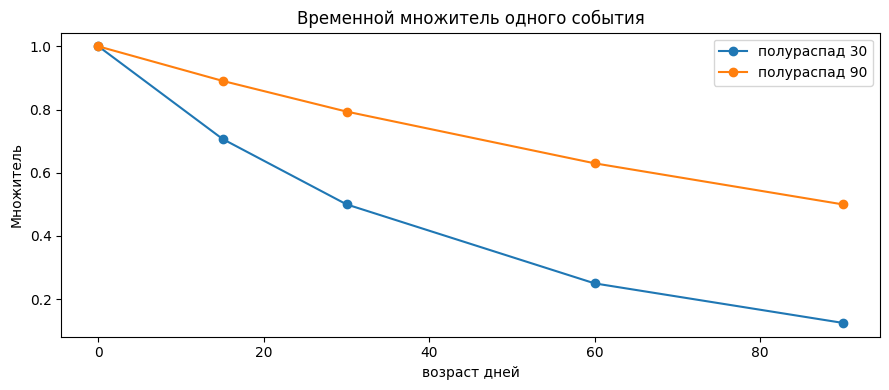

In [12]:
# Шаг М4.02.12 — Как убывает вес события
ages=np.array([0,15,30,60,90])
decays=pd.DataFrame({"возраст дней":ages,"полураспад 30":np.exp2(-ages/30),
                    "полураспад 90":np.exp2(-ages/90)})
display(decays)
decays.plot(x="возраст дней",y=["полураспад 30","полураспад 90"],marker="o")
plt.title("Временной множитель одного события");plt.ylabel("Множитель");plt.tight_layout();plt.show()

Ценовой штраф использует расстояние логарифмов. Это уменьшает влияние абсолютных различий дорогих товаров, но остаётся грубой общей гипотезой о диапазоне бюджета. Категории с разными ценовыми уровнями могут требовать отдельных моделей.

Включение нулевого штрафа и отсутствия затухания позволяет проверить, нужны ли эти усложнения. Если доступный признак не помогает критерию, его присутствие в источнике само по себе не оправдывает включение.

In [13]:
# Шаг М4.02.13 — Небольшая сетка настроек
records=[]
for half_life in [None,30,90]:
    for penalty in [0.0,0.1,0.3]:
        fitted=fit_content(ctx,half_life,penalty)
        metrics=summarize(fitted["scores"],ctx)
        records.append({"half_life":half_life if half_life is not None else 0,
                        "price_penalty":penalty,**metrics.to_dict()})
grid=pd.DataFrame(records).sort_values(["NDCG@K","price_penalty","half_life"],
                                      ascending=[False,True,True],kind="stable")
display(grid[["half_life","price_penalty","NDCG@K","Recall@K","Coverage"]].round(4))

,half_life,price_penalty,NDCG@K,Recall@K,Coverage
6,90,0.0,0.2658,0.3155,1.0000
0,0,0.0,0.2648,0.3129,1.0000
1,0,0.1,0.2540,0.3095,1.0000
3,30,0.0,0.2520,0.2966,1.0000
7,90,0.1,0.2508,0.3060,1.0000
4,30,0.1,0.2421,0.2966,0.9944
2,0,0.3,0.2058,0.2586,0.9611
8,90,0.3,0.2015,0.2552,0.9611
5,30,0.3,0.1976,0.2526,0.9556


Конфигурация фиксируется до майского расчёта. Правило разрешения равенств также является частью выбора: меньшая сложность предпочтительнее, если выбранный критерий не различает варианты.

Изменение параметров после просмотра теста превратило бы его в ещё одну валидационную выборку. Для нового независимого вывода тогда потребовался бы следующий период, которого этот эксперимент не использовал.

In [14]:
# Шаг М4.02.14 — Фиксация выбранной конфигурации
winner=grid.iloc[0]
chosen_half_life=None if winner.half_life==0 else float(winner.half_life)
chosen_penalty=float(winner.price_penalty)
chosen=fit_content(ctx,chosen_half_life,chosen_penalty)
display(pd.Series({"half_life":chosen_half_life,"price_penalty":chosen_penalty,
                   "правило выбора":"Максимум validation NDCG@10, затем меньшая сложность"}).to_frame("значение"))

,значение
half_life,90.0
price_penalty,0.0
правило выбора,"Максимум validation NDCG@10, затем меньшая сложность"


Сравнение с ненастроенным содержательным вариантом отделяет пользу самой идеи профиля от выигрыша дополнительных параметров. Сравнение с популярностью показывает, использована ли индивидуальная информация.

Генератор заложил интересы к категории и коллекции, поэтому успех соответствующих признаков ожидаем. Он подтверждает работоспособность механизма на известной структуре и не определяет победителя на любом реальном журнале.

In [15]:
# Шаг М4.02.15 — Сопоставление с базовым алгоритмом
display(pd.DataFrame({"популярность":summarize(popular_scores(ctx),ctx),
                      "содержание без настроек":summarize(base["scores"],ctx),
                      "выбранная конфигурация":summarize(chosen["scores"],ctx)}).T.round(4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
популярность,0.0303,0.0759,0.0608,0.2724,0.1,6.4356,290.0
содержание без настроек,0.1252,0.3129,0.2648,0.7931,1.0,7.8439,290.0
выбранная конфигурация,0.1262,0.3155,0.2658,0.8034,1.0,7.8392,290.0


Майская история включает апрельские действия, а выбранное правило остаётся неизменным. Это обновление доступной информации, предусмотренное протоколом. Все контрольные покупки мая находятся за границей обучения.

Разрез без истории измеряет качество запасного алгоритма. Его нельзя представлять как качество персонального содержательного профиля: профиль в этой группе отсутствует. Общая оценка отражает фактически возвращаемую систему целиком.

In [16]:
# Шаг М4.02.16 — Обновление истории и майская проверка
test_ctx=load_context("test")
test_model=fit_content(test_ctx,chosen_half_life,chosen_penalty)
display(summarize(test_model["scores"],test_ctx).round(4).to_frame("test"))
test_detail=evaluate(test_model["scores"],test_ctx)
test_detail["когорта"]=np.where(test_detail.history_size.eq(0),"без истории","с историей")
display(test_detail.groupby("когорта").agg(пользователей=("user_id","size"),NDCG=("ndcg","mean"),Recall=("recall","mean")).round(4))

,test
Precision@K,0.1157
Recall@K,0.2892
NDCG@K,0.2386
HitRate@K,0.7400
Coverage,1.0000
Novelty,7.6197
users,300.0000


,пользователей,NDCG,Recall
когорта,,,
без истории,10,0.0866,0.1250
с историей,290,0.2438,0.2948


Настройки выбраны по validation и перенесены без изменения в test. Обновление истории не смешано с повторным выбором параметров. Эффект дополнительных признаков оценивается сравнением с простым содержательным вариантом.

## Холодный старт, диагностические примеры и ограничения

У нового товара может быть ненулевой содержательный вектор при отсутствии поведенческой истории. Для нового пользователя персональный профиль отсутствует; требуется запасной алгоритм или явно сообщённые начальные предпочтения.

Объяснимость ограничена качеством признаков. Без сведений о совместимости, наличии, размерах и юридических ограничениях высокая содержательная близость сама по себе не делает товар допустимым к показу.

Холодная карточка получает содержательную оценку без поведенческой статистики. Это возможно только при наличии корректного описания на момент прогноза. Если описание отсутствует или целиком неизвестно словарю, этот путь тоже может оказаться пустым.

Ненулевая оценка не гарантирует показ: кандидат конкурирует с остальными карточками. Отдельная диагностика холодных товаров помогает проверить, что модель хотя бы способна оценивать их, не обращаясь к будущим событиям.

In [17]:
# Шаг М4.02.17 — Товар без взаимодействий в истории
new_columns=np.flatnonzero(np.asarray(ctx["B"].sum(axis=0)).ravel()==0)
display(catalog.iloc[new_columns][["product_id","category","collection","usage"]]
        .assign(оценка_пользователю_1=base["scores"][ui,new_columns]))
assert len(new_columns)==9

,product_id,category,collection,usage,оценка_пользователю_1
96,97,Одежда,премиальная,поездка,0.297740
115,120,Продукты,премиальная,поездка,0.626629
126,143,Электроника,премиальная,поездка,0.172453
134,164,Бытовая техника,премиальная,поездка,0.120495
145,189,Обувь,премиальная,поездка,0.261903
172,289,Книги,премиальная,поездка,0.147789
173,295,Красота,премиальная,поездка,0.172453
174,296,Дом и сад,премиальная,поездка,0.224777
179,388,Спорт,премиальная,поездка,0.172851


Новый пользователь и новый товар требуют разных запасных решений. У пользователя без истории нет взвешенной суммы карточек, даже если каталог идеально описан. Популярность является общим ориентиром, а не индивидуальным предпочтением.

В реальной системе отсутствие истории может быть вызвано сменой идентификатора или ограничениями хранения данных. Поэтому этот путь требуется как штатная часть алгоритма, а не только для демонстрации искусственно нового человека.

In [18]:
# Шаг М4.02.18 — Пустой профиль и запасной алгоритм
cold_user=300
cold_row=ctx["u_map"][cold_user]
assert ctx["seen"][cold_row].sum()==0
assert np.allclose(base["scores"][cold_row],ctx["popularity"])
cold_top=top_indices(base["scores"],ctx["seen"],5)[cold_row]
display(catalog.iloc[cold_top][["product_id","category","collection"]].assign(источник="популярность"))

,product_id,category,collection,источник
17,18,Красота,активная,популярность
102,106,Бытовая техника,базовая,популярность
34,35,Одежда,базовая,популярность
136,168,Дом и сад,премиальная,популярность
52,53,Одежда,активная,популярность


Явно введённые интересы создают отдельный начальный сигнал. Он может быть преобразован в то же пространство, но не является восстановленной историей и не должен подменяться скрытыми предпочтениями генератора.

Нулевой вектор после преобразования означает отсутствие известных признаков. Корректная обработка возвращает запасную выдачу или уточняет выбор, а не приписывает человеку персональный профиль по произвольному порядку карточек.

In [19]:
# Шаг М4.02.19 — Явно заданный стартовый интерес
onboarding="книги уютная дом"  # Иллюстративный ввод, не скрытая характеристика пользователя 300.
initial_profile=normalize(base["vectorizer"].transform([onboarding]))
onboarding_scores=(initial_profile@base["F"].T).toarray().ravel()
onboarding_order=np.argsort(-onboarding_scores,kind="stable")[:6]
display(catalog.iloc[onboarding_order][["product_id","category","collection","usage"]]
        .assign(оценка=onboarding_scores[onboarding_order]))

,product_id,category,collection,usage,оценка
107,112,Книги,уютная,дом,1.000000
167,269,Книги,уютная,дом,1.000000
144,187,Книги,уютная,поездка,0.803898
21,22,Книги,уютная,подарок,0.791142
154,217,Книги,уютная,подарок,0.791142
3,4,Книги,базовая,дом,0.704467


Совпадающие строки признаков создают одинаковые оценки при любом данном профиле. Изменение формулы сортировки не восстановит сведения, отсутствующие в представлении. Необходимы новые полезные характеристики, а не более точная запись прежнего числа.

Такое ограничение помогает выбрать направление работы: исправление каталога, добавление доступных свойств или подключение поведенческого источника. Последний способен различать объекты, которые одинаковы по записанному содержанию.

In [20]:
# Шаг М4.02.20 — Сколько карточек признаки не различают
feature_groups=catalog.groupby(["category","collection","usage"]).size().rename("карточек")
display(feature_groups.value_counts().sort_index().rename_axis("размер группы").to_frame("групп"))
print("Групп признаков:",len(feature_groups),"товаров:",len(catalog))
display(pd.Series({"число допустимых ненулевых координат профиля":base["profiles"].shape[1],
                   "полезность зависит от": "Полноты и достоверности описаний, а не длины названия"}).to_frame("значение"))

,групп
размер группы,
1,36
2,72


Групп признаков: 108 товаров: 180


,значение
число допустимых ненулевых координат профиля,18
полезность зависит от,"Полноты и достоверности описаний, а не длины названия"


Практический результат — содержательная модель с профилем пользователя, разбором вкладов, проверкой давности и цены, независимым тестом и явным запасным путём.

Содержательное сходство не заменяет проверку допустимости товара и не охватывает интересы, отсутствующие в признаках. Однообразие профиля и зависимость от описаний остаются ограничениями.

Источники: [TfidfVectorizer](https://scikit-learn.org/1.8/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [нормировка векторов](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.normalize.html).